# V29 AllGlobal W1024 standalone × CarRacing-v3
[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vtavakkoli/simple-jev/blob/main/notebooks/Laya_V29_CarRacing_Standalone_Colab.ipynb)

Based on the original [CarRacing notebook](https://github.com/vtavakkoli/simple-jev/blob/main/notebooks/Laya_CarRacing_Local_Colab.ipynb). Uses your [standalone V29 checkpoint](https://huggingface.co/vtava/Laya-V29-AllGlobal-W1024-Standalone) via its own packaged load_model.py and runtime.py: no installation of laya or tinycenn_lm.

Select **GPU / T4** in Colab. The checkpoint is **private**: add an HF_TOKEN with read access using Colab Secrets. Loading executes the model repository's custom Python runtime code; pin and review the revision you trust.

**Scientific warning:** V29 was trained as a typed-decision classifier, not a driving policy. This notebook checks whether it can generalize to road states. The hybrid controller can drive through deterministic steering and anti-stall corrections, so road reward alone does NOT demonstrate model ability. Inspect *raw* steering accuracy, correction rate and actual model contribution. Set CONTROL_MODE to "raw_laya" for a diagnostic test of its uncorrected discrete choices (the continuous actuator mapping still uses vision). Raw softmax scores are not calibrated safety probabilities.


In [1]:
#@title 1. Install CarRacing + V29 standalone requirements
!apt-get -qq update
!apt-get -qq install -y swig > /dev/null
%pip -q install "gymnasium[box2d]==1.3.0" "transformers==4.57.6" "huggingface_hub>=0.25,<1" "safetensors>=0.4" imageio imageio-ffmpeg pillow matplotlib pandas


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 93.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 94.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 65.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 41.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 89.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 100.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 

In [2]:
#@title 2. Imports and experiment settings
import os
os.environ["USE_TF"] = "0"

import time, json
from collections import Counter, deque
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import gymnasium as gym
import imageio.v2 as imageio
import matplotlib.pyplot as plt

from PIL import Image as PILImage
from IPython.display import Video, Image, display
from huggingface_hub import snapshot_download

MODEL_ID = "vtava/Laya-V29-AllGlobal-W1024-Standalone"
MODEL_REVISION = "main" # use a commit SHA to pin weights/runtime
MODEL_KEY = "v29-standalone"
ENV_ID = "CarRacing-v3"
SEED = 0

SIM_FPS = 50.0
MAX_STEPS = 3000

# The camera still gets one second, but the car is no longer held motionless for all of it.
CAMERA_WARMUP_FRAMES = 50
CAMERA_SETTLE_FRAMES = 8
MODEL_WARMUP_CALLS = 6

CONTROL_HORIZON = 4
HISTORY_LEN = 3
CONTROL_MODE = "confidence_hybrid"   # "confidence_hybrid" or "raw_laya"

# Runtime protection. These do NOT fake Laya confidence; all intervention is logged.
CONFIDENCE_FOR_FULL_TRUST = 0.35
MIN_CONSISTENT_LAYA_BLEND = 0.25
MAX_LAYA_BLEND = 0.85
ANTI_STALL_SPEED = 4.0
RECOVERY_AFTER_FRAMES = 120
STOP_AFTER_FRAMES = 500

MAX_STEER_DELTA_PER_FRAME = 0.16
MAX_LONGITUDINAL_DELTA_PER_FRAME = 0.16

VIDEO_EVERY = 2
GIF_EVERY = 6
SCAN_ROWS = [68, 62, 56, 50, 44, 38]  # near -> far

OUTPUT_DIR = Path("/content") if Path("/content").exists() else Path.cwd()
VIDEO_PATH = str(OUTPUT_DIR / "v29_car_racing_w1024.mp4")
GIF_PATH = str(OUTPUT_DIR / "v29_car_racing_w1024.gif")
LOG_PATH = str(OUTPUT_DIR / "v29_car_racing_w1024.json")
CSV_PATH = str(OUTPUT_DIR / "v29_car_racing_w1024_decisions.csv")
PREFLIGHT_PATH = str(OUTPUT_DIR / "v29_car_racing_w1024_preflight.json")

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    torch.backends.cuda.matmul.allow_tf32 = True

print("device:", DEVICE)
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


if DEVICE != "cuda":
    print("WARNING: CPU inference for 423M parameters may be very slow.")
print("model:", MODEL_ID, "revision:", MODEL_REVISION, "device:", DEVICE)
print("control mode:", CONTROL_MODE)


device: cuda
GPU: Tesla T4
model: vtava/Laya-V29-AllGlobal-W1024-Standalone revision: main device: cuda
control mode: confidence_hybrid


In [3]:
#@title 3. Download your private standalone model and adapt to the Router interface
import importlib.util
import sys

HF_TOKEN = os.getenv("HF_TOKEN")
try:
    from google.colab import userdata
    HF_TOKEN = HF_TOKEN or userdata.get("HF_TOKEN")
except Exception:
    pass
try:
    MODEL_DIR = Path(snapshot_download(
        repo_id=MODEL_ID, revision=MODEL_REVISION,
        repo_type="model", token=HF_TOKEN,
    ))
except Exception as exc:
    raise RuntimeError(
        "Unable to download private model: put a READ-enabled HF_TOKEN in Colab Secrets, "
        "grant this notebook access, or call huggingface_hub.login() and retry."
    ) from exc
required_files = ("bundle.json", "load_model.py", "runtime.py", "model.safetensors")
missing_files = [f for f in required_files if not (MODEL_DIR / f).is_file()]
if missing_files:
    raise FileNotFoundError(f"Incomplete V29 standalone bundle: {missing_files}")
MANIFEST = json.loads((MODEL_DIR / "bundle.json").read_text(encoding="utf-8"))
assert MANIFEST.get("architecture") == "laya-v29-fastwindow", MANIFEST
assert MANIFEST.get("runtime_format") == 1, MANIFEST
MODEL_MAX_LEN = int(MANIFEST.get("max_len", 512))
assert MODEL_MAX_LEN >= 128
print("Model directory:", MODEL_DIR)
print("Architecture:", MANIFEST["architecture"])
print("Full-context window:", MANIFEST.get("window"))
print("Converted global layers:", MANIFEST.get("global_layers"))
print("Maximum input length:", MODEL_MAX_LEN)

def load_module(name, file):
    spec = importlib.util.spec_from_file_location(name, str(file))
    if spec is None or spec.loader is None:
        raise RuntimeError(f"Cannot import module: {file}")
    module = importlib.util.module_from_spec(spec)
    sys.modules[name] = module
    spec.loader.exec_module(module)
    return module

# From your OWN standalone bundle; the model's full checkpoint is validated strictly.
v29_loader = load_module("_v29_loader", MODEL_DIR / "load_model.py")
v29_runtime = load_module("_v29_runtime", MODEL_DIR / "runtime.py")
v29_model, v29_tokenizer = v29_loader.load_model(MODEL_DIR, device=DEVICE)
assert v29_tokenizer is not None
v29_model.eval()

class V29RouterAdapter:
    """Converts V29's choice_index, ordered probabilities into Router-shaped answers."""
    def __init__(self, model, tokenizer, runtime, max_len, device):
        self.model = model
        self.tokenizer = tokenizer
        self.runtime = runtime
        self.max_len = max_len
        self.device = device
        self.total_questions = 0

    def predict(self, state, questions, model=None):
        if model not in (None, MODEL_KEY):
            raise ValueError(f"Unexpected model: {model}")
        answers = {}
        for name, question in questions.items():
            if question.get("type", "choice") != "choice":
                raise ValueError("Only typed-decision choice questions supported")
            labels = list(question["criteria"].keys())
            output = self.runtime.predict(
                self.model, self.tokenizer, state, question,
                max_len=self.max_len, device=self.device,
            )
            probs = np.asarray(output["probabilities"], dtype=np.float64)
            idx = int(output["choice_index"])
            if (len(probs) != len(labels) or not 0 <= idx < len(labels)
                    or not np.all(np.isfinite(probs)) or np.any(probs < 0)
                    or not np.isclose(probs.sum(), 1, atol=1e-3)):
                raise ValueError(f"Invalid V29 output for {name}: {output}")
            pmax = float(probs[idx])
            uniform = 1.0 / len(labels)
            # Pmax is not calibrated confidence! Subtract chance baseline.
            strength = float(np.clip((pmax-uniform)/(1-uniform), 0, 1))
            answers[name] = {
                "choice": labels[idx],
                "confidence": strength,
                "probabilities": dict(zip(labels, map(float, probs))),
                "softmax_probability": pmax,
            }
            self.total_questions += 1
        return {"answers": answers}

router = V29RouterAdapter(v29_model, v29_tokenizer, v29_runtime,
                          MODEL_MAX_LEN, DEVICE)
print("V29 fully loaded and Router-compatible (without laya / tinycenn_lm)")


Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

runtime.py: 0.00B [00:00, ?B/s]

bundle.json:   0%|          | 0.00/440 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

requirements.txt:   0%|          | 0.00/71.0 [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

training_report.json: 0.00B [00:00, ?B/s]

Model directory: /root/.cache/huggingface/hub/models--vtava--Laya-V29-AllGlobal-W1024-Standalone/snapshots/39d8fb55197ff41e893f032db227937e15804b6b
Architecture: laya-v29-fastwindow
Full-context window: 1024
Converted global layers: [0, 3, 6, 9, 12, 15, 18, 21, 24, 27]
Maximum input length: 512
V29 fully loaded and Router-compatible (without laya / tinycenn_lm)


In [4]:
#@title 3. Road perception and vehicle telemetry
def road_mask_from_rgb(frame):
    img = np.asarray(frame, dtype=np.float32)
    # CarRacing asphalt is mostly grey: low RGB spread, mid brightness.
    spread = np.ptp(img, axis=2)
    mean = img.mean(axis=2)
    mask = (spread < 26) & (mean > 48) & (mean < 190)
    # Remove dashboard / car region.
    mask[82:] = False
    return mask

def _contiguous_groups(xs, max_gap=8):
    if len(xs) == 0:
        return []
    return np.split(xs, np.where(np.diff(xs) > max_gap)[0] + 1)

def scan_road(mask):
    previous_center = 48.0
    centers, widths, valid = [], [], []

    for y in SCAN_ROWS:
        # Use a 3-row band so single-pixel texture holes do not dominate.
        band = mask[max(0, y-1):min(96, y+2)].mean(axis=0)
        xs = np.flatnonzero(band >= 0.34)
        groups = [g for g in _contiguous_groups(xs) if len(g) >= 4]

        if not groups:
            centers.append(None)
            widths.append(0.0)
            valid.append(False)
            continue

        # Continuity prior: prefer the road segment nearest the previous scanline center.
        g = min(
            groups,
            key=lambda z: (
                abs((float(z[0]) + float(z[-1])) / 2.0 - previous_center),
                -len(z),
            ),
        )
        previous_center = (float(g[0]) + float(g[-1])) / 2.0
        centers.append((previous_center - 48.0) / 48.0)
        widths.append((float(g[-1]) - float(g[0]) + 1.0) / 96.0)
        valid.append(True)

    return centers, widths, valid

def read_speed(env):
    try:
        return float(np.linalg.norm(env.unwrapped.car.hull.linearVelocity))
    except Exception:
        return 0.0

def read_angular_velocity(env):
    try:
        return float(env.unwrapped.car.hull.angularVelocity)
    except Exception:
        return 0.0

def _direction_label(angle):
    if angle is None:
        return "unknown"
    if angle < -11:
        return "strong_left"
    if angle < -2.5:
        return "left"
    if angle > 11:
        return "strong_right"
    if angle > 2.5:
        return "right"
    return "straight"

def extract_visual_state(frame, speed, angular_velocity=0.0):
    centers, widths, valid = scan_road(road_mask_from_rgb(frame))
    rows = [(y, c) for y, c, ok in zip(SCAN_ROWS, centers, valid) if ok]

    # Bearing: road-center displacement at the middle look-ahead row.
    target = min(rows, key=lambda row: abs(row[0] - 50)) if rows else None
    bearing = (
        float(np.degrees(np.arctan2(48.0 * target[1], 72.0 - target[0])))
        if target else None
    )

    # Heading: how the road center moves from near to far.
    heading = (
        float(np.degrees(np.arctan2(
            48.0 * (rows[-1][1] - rows[0][1]),
            rows[0][0] - rows[-1][0]
        )))
        if len(rows) >= 2 else None
    )

    combined = None
    if bearing is not None:
        combined = float(bearing + 0.40 * (heading if heading is not None else 0.0))

    speed_band = (
        "stopped" if speed < 3 else
        "slow" if speed < 10 else
        "turn_speed" if speed < 17 else
        "cruise" if speed < 25 else
        "fast" if speed < 34 else
        "very_fast"
    )

    visibility = float(np.mean(valid))
    return {
        "visible_road_bearing_degrees": bearing,
        "visible_road_heading_degrees": heading,
        "combined_road_angle_degrees": combined,
        "road_direction": _direction_label(combined),
        "road_center_offsets_near_to_far": centers,
        "road_width_fraction_near_to_far": widths,
        "scanline_valid": valid,
        "road_visibility": visibility,
        "near_center_offset": rows[0][1] if rows else None,
        "far_center_offset": rows[-1][1] if rows else None,
        "speed": float(speed),
        "speed_band": speed_band,
        "angular_velocity": float(angular_velocity),
    }

def perception_overlay(frame):
    out = np.asarray(frame).copy()
    mask = road_mask_from_rgb(frame)
    out[mask] = (0.62 * out[mask] + 0.38 * np.array([255, 255, 0])).astype(np.uint8)

    centers, _, valid = scan_road(mask)
    for y, c, ok in zip(SCAN_ROWS, centers, valid):
        if ok:
            x = int(np.clip(round(48 + 48 * c), 0, 95))
            out[max(0,y-1):min(96,y+2), max(0,x-1):min(96,x+2)] = [255, 0, 255]
    return out


In [5]:
#@title 4. Deterministic visual reference controller + camera/launch warm-up
def reference_control(vision, force_launch=False):
    """Low-level geometric reference used for warm-up, confidence gating and recovery."""
    b = vision.get("visible_road_bearing_degrees")
    h = vision.get("visible_road_heading_degrees")
    vis = float(vision.get("road_visibility", 0.0))
    speed = float(vision.get("speed", 0.0))

    b = 0.0 if b is None else float(b)
    h = 0.0 if h is None else float(h)

    # Negative geometry -> negative steering (left); positive -> right.
    steer = float(np.clip(0.026 * b + 0.010 * h, -0.82, 0.82))

    turn_load = max(abs(b), 0.65 * abs(h))
    target_speed = float(np.clip(29.0 - 0.72 * turn_load, 10.0, 29.0))

    if vis < 0.34:
        # If vision is lost, do not accelerate hard blindly.
        longitudinal = -0.18 if speed > 14.0 else 0.10
    elif force_launch and speed < 12.0:
        longitudinal = 0.58
    elif speed < target_speed - 3.0:
        longitudinal = 0.46
    elif speed > target_speed + 3.0:
        longitudinal = -0.20
    else:
        longitudinal = 0.12

    return np.array([steer, longitudinal], dtype=np.float32)

def to_gym_action(control):
    steer, longitudinal = np.asarray(control, dtype=np.float32)
    steer = float(np.clip(steer, -1.0, 1.0))
    longitudinal = float(np.clip(longitudinal, -1.0, 1.0))
    return np.array(
        [steer, max(longitudinal, 0.0), max(-longitudinal, 0.0)],
        dtype=np.float32,
    )

def slew(previous, target):
    previous = np.asarray(previous, dtype=np.float32)
    target = np.asarray(target, dtype=np.float32)
    delta = np.clip(
        target - previous,
        [-MAX_STEER_DELTA_PER_FRAME, -MAX_LONGITUDINAL_DELTA_PER_FRAME],
        [ MAX_STEER_DELTA_PER_FRAME,  MAX_LONGITUDINAL_DELTA_PER_FRAME],
    )
    return (previous + delta).astype(np.float32)

def reset_and_warmup(env, seed, record_frames=None):
    """One-second camera warm-up that also launches the car after a short settle period."""
    obs, info = env.reset(seed=seed)
    total_reward = 0.0
    control = np.zeros(2, dtype=np.float32)

    for i in range(CAMERA_WARMUP_FRAMES):
        vision = extract_visual_state(obs, read_speed(env), read_angular_velocity(env))

        if i < CAMERA_SETTLE_FRAMES:
            target = np.zeros(2, dtype=np.float32)
        else:
            target = reference_control(vision, force_launch=True)
            # Critical v2 fix: warm-up may not leave the vehicle stationary.
            if vision["speed"] < 8.0:
                target[1] = max(float(target[1]), 0.55)

        control = slew(control, target)
        action = to_gym_action(control)
        if not env.action_space.contains(action):
            raise RuntimeError(f"Warm-up action outside CarRacing action space: {action}")

        obs, reward, terminated, truncated, info = env.step(action)
        total_reward += float(reward)

        if record_frames is not None:
            record_frames.append(env.render())

        if terminated or truncated:
            raise RuntimeError(f"Environment ended during camera/launch warm-up at frame {i+1}")

    final_vision = extract_visual_state(obs, read_speed(env), read_angular_velocity(env))
    return obs, info, total_reward, control, final_vision


In [6]:
#@title 6. Compatible V29 choice schema + explicit semantic contract
STEERING_INTENT = {
    "left": "the visible road is to the LEFT of the car or bends left",
    "straight": "the visible road is centered; no meaningful left/right correction is needed",
    "right": "the visible road is to the RIGHT of the car or bends right",
}

LONGITUDINAL_INTENT = {
    "accelerate": "gain or maintain speed when road is visible and the car is stopped or slow",
    "hold": "speed is already appropriate; use light throttle rather than braking",
    "brake": "reduce speed because the car is fast/very_fast, road is lost, or a severe high-speed turn requires slowing",
}

QUESTIONS = {
    "steering": {
        "type": "choice",
        "instructions": (
            "Choose steering direction only from road_direction. "
            "strong_left/left => left; straight => straight; strong_right/right => right. "
            "Do not infer the opposite direction."
        ),
        "criteria": STEERING_INTENT,
    },
    "longitudinal": {
        "type": "choice",
        "instructions": (
            "Choose speed intent from the numeric speed and road visibility. "
            "HARD RULES: if road_visibility >= 0.34 and speed < 10, choose accelerate. "
            "If speed >= 34, choose brake. "
            "If road_visibility < 0.34 and speed > 14, choose brake. "
            "Otherwise use hold/accelerate as appropriate. "
            "Never choose hold for a stopped car and never choose accelerate at excessive speed."
        ),
        "criteria": LONGITUDINAL_INTENT,
    },
}

def _field(x, key, default=None):
    return x.get(key, default) if isinstance(x, dict) else getattr(x, key, default)

def _validate_choice(answer, choices, name):
    choice = _field(answer, "choice")
    confidence = float(_field(answer, "confidence", 0.0))
    probabilities = dict(_field(answer, "probabilities", {}) or {})

    if choice not in choices:
        raise ValueError(f"Invalid {name} choice: {choice!r}")
    if not np.isfinite(confidence) or not 0.0 <= confidence <= 1.0:
        raise ValueError(f"Invalid {name} confidence: {confidence!r}")

    clean = {}
    for k, v in probabilities.items():
        v = float(v)
        if k in choices and np.isfinite(v) and 0.0 <= v <= 1.0:
            clean[str(k)] = v

    sorted_p = sorted(clean.values(), reverse=True)
    top_probability = float(clean.get(choice, sorted_p[0] if sorted_p else confidence))
    margin = float(sorted_p[0] - sorted_p[1]) if len(sorted_p) >= 2 else top_probability

    return {
        "choice": choice,
        "confidence": confidence,
        "probabilities": clean,
        "choice_probability": top_probability,
        "probability_margin": margin,
    }

def expected_steering_from_vision(vision):
    d = vision.get("road_direction", "unknown")
    if d in ("strong_left", "left"):
        return "left"
    if d in ("strong_right", "right"):
        return "right"
    if d == "straight":
        return "straight"
    return "unknown"

def _override_answer(answer, desired, field_name, reason, overrides):
    if desired is None or answer["choice"] == desired:
        return dict(answer)

    old = answer["choice"]
    out = dict(answer)
    out["model_choice"] = old
    out["model_confidence"] = float(answer["confidence"])
    out["model_choice_probability"] = float(answer.get("choice_probability", 0.0))
    out["choice"] = desired
    out["choice_probability"] = float(answer.get("probabilities", {}).get(desired, 0.0))
    out["probability_margin"] = 0.0
    out["semantic_override"] = reason
    overrides.append({
        "field": field_name,
        "from": old,
        "to": desired,
        "reason": reason,
    })
    return out

def enforce_semantic_contract(state, steering, longitudinal):
    """Correct only objectively contradictory discrete intents.

    Raw model answers are preserved separately. Any correction forces effective
    model confidence to zero so hybrid control falls back to the deterministic
    visual reference rather than pretending the corrected label was a confident
    Laya prediction.
    """
    overrides = []

    direction = state.get("road_direction", "unknown")
    expected_s = {
        "strong_left": "left",
        "left": "left",
        "straight": "straight",
        "right": "right",
        "strong_right": "right",
    }.get(direction)

    steering_fixed = _override_answer(
        steering, expected_s, "steering", "road_direction_contract", overrides
    )

    speed = float(state.get("speed", 0.0))
    visibility = float(state.get("road_visibility", 0.0))
    bearing = state.get("bearing_degrees")
    heading = state.get("heading_degrees")
    bearing = 0.0 if bearing is None else float(bearing)
    heading = 0.0 if heading is None else float(heading)
    turn_load = max(abs(bearing), 0.65 * abs(heading))

    desired_l = None
    reason_l = None
    if visibility >= 0.34 and speed < 10.0:
        desired_l = "accelerate"
        reason_l = "visible_road_low_speed_contract"
    elif speed >= 34.0:
        desired_l = "brake"
        reason_l = "excessive_speed_contract"
    elif visibility < 0.34 and speed > 14.0:
        desired_l = "brake"
        reason_l = "lost_road_contract"
    elif turn_load >= 18.0 and speed > 24.0:
        desired_l = "brake"
        reason_l = "severe_turn_contract"

    longitudinal_fixed = _override_answer(
        longitudinal, desired_l, "longitudinal", reason_l, overrides
    )

    return steering_fixed, longitudinal_fixed, overrides

def laya_numeric_target(steering_choice, longitudinal_choice, vision):
    b = vision.get("visible_road_bearing_degrees")
    h = vision.get("visible_road_heading_degrees")
    b = 0.0 if b is None else float(b)
    h = 0.0 if h is None else float(h)

    magnitude = float(np.clip(0.10 + 0.022 * abs(b) + 0.008 * abs(h), 0.10, 0.82))
    steer = {"left": -magnitude, "straight": 0.0, "right": magnitude}[steering_choice]
    longitudinal = {"accelerate": 0.52, "hold": 0.14, "brake": -0.22}[longitudinal_choice]
    return np.array([steer, longitudinal], dtype=np.float32)

class LayaCarRacingPolicy:
    def __init__(self, router):
        self.router = router
        self.history = deque(maxlen=HISTORY_LEN)

    def state(self, vision, episode_return, step, current_control):
        recent = []
        for h in self.history:
            recent.append({
                "steering": h["steering"],
                "longitudinal": h["longitudinal"],
                "reward": round(float(h["reward"]), 2),
                "tiles": int(h["tiles"]),
                "speed_after": round(float(h["speed_after"]), 1),
                "road_after": h["road_after"],
            })

        return {
            "task": "drive a car on the visible road and keep visiting track tiles",
            "step": int(step),
            "road_direction": vision.get("road_direction"),
            "road_visibility": round(float(vision.get("road_visibility", 0.0)), 2),
            "bearing_degrees": None if vision.get("visible_road_bearing_degrees") is None else round(float(vision["visible_road_bearing_degrees"]), 1),
            "heading_degrees": None if vision.get("visible_road_heading_degrees") is None else round(float(vision["visible_road_heading_degrees"]), 1),
            "speed_band": vision.get("speed_band"),
            "speed": round(float(vision.get("speed", 0.0)), 1),
            "current_steer": round(float(current_control[0]), 2),
            "current_longitudinal": round(float(current_control[1]), 2),
            "episode_return": round(float(episode_return), 1),
            "recent_outcomes": recent,
        }

    def call(self, state):
        if DEVICE == "cuda":
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        response = self.router.predict(state, QUESTIONS, model=MODEL_KEY)
        if DEVICE == "cuda":
            torch.cuda.synchronize()
        latency_ms = (time.perf_counter() - t0) * 1000.0

        answers = _field(response, "answers", {})
        raw_steering = _validate_choice(answers["steering"], STEERING_INTENT, "steering")
        raw_longitudinal = _validate_choice(
            answers["longitudinal"], LONGITUDINAL_INTENT, "longitudinal"
        )

        steering, longitudinal, overrides = enforce_semantic_contract(
            state, raw_steering, raw_longitudinal
        )
        model_confidence = min(
            raw_steering["confidence"], raw_longitudinal["confidence"]
        )
        effective_confidence = 0.0 if overrides else model_confidence

        return {
            "raw_steering_answer": raw_steering,
            "raw_longitudinal_answer": raw_longitudinal,
            "steering_answer": steering,
            "longitudinal_answer": longitudinal,
            "semantic_overrides": overrides,
            "model_confidence": float(model_confidence),
            "confidence": float(effective_confidence),
            "latency_ms": float(latency_ms),
        }

    def decide(self, vision, episode_return, step, current_control):
        state = self.state(vision, episode_return, step, current_control)
        d = self.call(state)
        d["state"] = state
        d["raw_model_target"] = laya_numeric_target(
            d["raw_steering_answer"]["choice"],
            d["raw_longitudinal_answer"]["choice"],
            vision,
        )
        d["raw_target"] = laya_numeric_target(
            d["steering_answer"]["choice"],
            d["longitudinal_answer"]["choice"],
            vision,
        )
        return d

    def record(self, decision, reward, tiles, vision_after):
        self.history.append({
            "steering": decision["steering_answer"]["choice"],
            "longitudinal": decision["longitudinal_answer"]["choice"],
            "reward": float(reward),
            "tiles": int(tiles),
            "speed_after": float(vision_after["speed"]),
            "road_after": vision_after["road_direction"],
        })

print("✓ compact Laya intent policy + semantic contract ready")


✓ compact Laya intent policy + semantic contract ready


In [7]:
#@title 6. Model warm-up and semantic preflight
def synthetic_vision(direction, speed):
    angle = {
        "strong_left": -20.0, "left": -8.0, "straight": 0.0,
        "right": 8.0, "strong_right": 20.0, "unknown": None,
    }[direction]
    return {
        "visible_road_bearing_degrees": angle,
        "visible_road_heading_degrees": 0.5 * angle if angle is not None else None,
        "combined_road_angle_degrees": angle,
        "road_direction": direction,
        "road_center_offsets_near_to_far": [0.0] * len(SCAN_ROWS),
        "road_width_fraction_near_to_far": [0.25] * len(SCAN_ROWS),
        "scanline_valid": [direction != "unknown"] * len(SCAN_ROWS),
        "road_visibility": 1.0 if direction != "unknown" else 0.0,
        "near_center_offset": 0.0 if direction != "unknown" else None,
        "far_center_offset": 0.0 if direction != "unknown" else None,
        "speed": float(speed),
        "speed_band": "stopped" if speed < 3 else "slow" if speed < 10 else "cruise" if speed < 25 else "very_fast",
        "angular_velocity": 0.0,
    }

warm_policy = LayaCarRacingPolicy(router)
warm_state = warm_policy.state(
    synthetic_vision("straight", 6.0),
    episode_return=0.0,
    step=0,
    current_control=np.zeros(2, dtype=np.float32),
)

print("=== MODEL WARM-UP ===")
warm_latencies = []
model_warmup_t0 = time.perf_counter()
for i in range(MODEL_WARMUP_CALLS):
    d = warm_policy.call(warm_state)
    warm_latencies.append(d["latency_ms"])
    raw_pair = (
        f"{d['raw_steering_answer']['choice']}/"
        f"{d['raw_longitudinal_answer']['choice']}"
    )
    final_pair = (
        f"{d['steering_answer']['choice']}/"
        f"{d['longitudinal_answer']['choice']}"
    )
    correction = "" if raw_pair == final_pair else f" | raw={raw_pair} -> contract={final_pair}"
    print(
        f"warm-up {i+1}/{MODEL_WARMUP_CALLS} | "
        f"{final_pair} | conf={d['confidence']:.3f} | "
        f"model_conf={d['model_confidence']:.3f} | {d['latency_ms']:.1f} ms"
        f"{correction}"
    )

model_warmup_wall_ms = (time.perf_counter() - model_warmup_t0) * 1000.0
if len(warm_latencies) > 1:
    print("first-call latency:", round(warm_latencies[0], 1), "ms")
    print("post-warm-up mean:", round(float(np.mean(warm_latencies[1:])), 1), "ms")

def run_preflight():
    p = LayaCarRacingPolicy(router)

    # Every semantic contract case is blocking. The raw model answer is also
    # reported, so a PASS never hides whether the contract corrected Laya.
    cases = [
        {"name": "left_slow", "direction": "left", "speed": 7.0,
         "expected_s": "left", "expected_l": "accelerate", "required": True},
        {"name": "straight_stopped", "direction": "straight", "speed": 0.0,
         "expected_s": "straight", "expected_l": "accelerate", "required": True},
        {"name": "right_slow", "direction": "right", "speed": 7.0,
         "expected_s": "right", "expected_l": "accelerate", "required": True},
        {"name": "straight_fast", "direction": "straight", "speed": 38.0,
         "expected_s": "straight", "expected_l": "brake", "required": True},
    ]

    rows = []
    print("\n=== SEMANTIC PREFLIGHT ===")
    for case in cases:
        name = case["name"]
        expected_s = case["expected_s"]
        expected_l = case["expected_l"]
        required = bool(case["required"])

        v = synthetic_vision(case["direction"], case["speed"])
        d = p.decide(v, 0.0, 0, np.zeros(2, np.float32))

        raw_s = d["raw_steering_answer"]["choice"]
        raw_l = d["raw_longitudinal_answer"]["choice"]
        got_s = d["steering_answer"]["choice"]
        got_l = d["longitudinal_answer"]["choice"]

        raw_pair = f"{raw_s}/{raw_l}"
        final_pair = f"{got_s}/{got_l}"
        expected_pair = f"{expected_s}/{expected_l}"
        passed = final_pair == expected_pair

        status = "PASS" if passed else "FAIL"
        row = {
            "case": name,
            "required": required,
            "status": status,
            "passed": bool(passed),
            "expected": expected_pair,
            "raw_model": raw_pair,
            "got": final_pair,
            "semantic_overrides": d["semantic_overrides"],
            "model_confidence": float(d["model_confidence"]),
            "effective_confidence": float(d["confidence"]),
            "latency_ms": float(d["latency_ms"]),
        }
        rows.append(row)

        correction = ""
        if raw_pair != final_pair:
            correction = f" | raw {raw_pair:>18s} -> contract"

        print(
            f"{name:18s} {status:4s} | "
            f"expected {expected_pair:>18s} | got {final_pair:>18s} | "
            f"model_conf={d['model_confidence']:.3f} | "
            f"effective_conf={d['confidence']:.3f} | blocking"
            f"{correction}"
        )

    Path(PREFLIGHT_PATH).write_text(
        json.dumps(rows, indent=2, allow_nan=False), encoding="utf-8"
    )

    all_ok = all(r["passed"] for r in rows)
    return all_ok, rows

PREFLIGHT_PASSED, PREFLIGHT_RESULTS = run_preflight()
print("preflight passed:", PREFLIGHT_PASSED)


=== MODEL WARM-UP ===
warm-up 1/6 | straight/accelerate | conf=0.000 | model_conf=0.527 | 1760.9 ms | raw=straight/hold -> contract=straight/accelerate
warm-up 2/6 | straight/accelerate | conf=0.000 | model_conf=0.527 | 198.2 ms | raw=straight/hold -> contract=straight/accelerate
warm-up 3/6 | straight/accelerate | conf=0.000 | model_conf=0.527 | 136.7 ms | raw=straight/hold -> contract=straight/accelerate
warm-up 4/6 | straight/accelerate | conf=0.000 | model_conf=0.527 | 136.1 ms | raw=straight/hold -> contract=straight/accelerate
warm-up 5/6 | straight/accelerate | conf=0.000 | model_conf=0.527 | 135.8 ms | raw=straight/hold -> contract=straight/accelerate
warm-up 6/6 | straight/accelerate | conf=0.000 | model_conf=0.527 | 134.9 ms | raw=straight/hold -> contract=straight/accelerate
first-call latency: 1760.9 ms
post-warm-up mean: 148.3 ms

=== SEMANTIC PREFLIGHT ===
left_slow          PASS | expected    left/accelerate | got    left/accelerate | model_conf=0.529 | effective_conf=0.

In [8]:
#@title 8. Audit RAW model decisions (before any safety or semantic corrections)
# This evaluates V29 directly, not enforced output.
AUDIT_CASES = [
    ("left_stopped", "left", 0., "left", "accelerate"),
    ("right_stopped", "right", 0., "right", "accelerate"),
    ("straight_stopped", "straight", 0., "straight", "accelerate"),
    ("left_slow", "left", 7., "left", "accelerate"),
    ("right_slow", "right", 7., "right", "accelerate"),
    ("straight_slow", "straight", 7., "straight", "accelerate"),
    ("strong_left", "strong_left", 7., "left", "accelerate"),
    ("strong_right", "strong_right", 7., "right", "accelerate"),
    ("left_fast", "left", 38., "left", "brake"),
    ("right_fast", "right", 38., "right", "brake"),
    ("straight_fast", "straight", 38., "straight", "brake"),
]
raw_audit_rows = []
for name, direction, speed, expected_s, expected_l in AUDIT_CASES:
    vision = synthetic_vision(direction, speed)
    state = LayaCarRacingPolicy(router).state(
        vision, 0., 0, np.zeros(2, dtype=np.float32)
    )
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    answers = router.predict(state, QUESTIONS, model=MODEL_KEY)["answers"]
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    raw_audit_rows.append({
        "case": name, "expected_steer": expected_s,
        "model_steer": answers["steering"]["choice"],
        "steer_correct": answers["steering"]["choice"] == expected_s,
        "expected_long": expected_l,
        "model_long": answers["longitudinal"]["choice"],
        "long_correct": answers["longitudinal"]["choice"] == expected_l,
        "steer_softmax_pmax": answers["steering"]["softmax_probability"],
        "long_softmax_pmax": answers["longitudinal"]["softmax_probability"],
        "two_question_ms": 1000*(time.perf_counter()-t0),
    })
RAW_AUDIT = pd.DataFrame(raw_audit_rows)
display(RAW_AUDIT)
RAW_STEER_ACC = float(RAW_AUDIT["steer_correct"].mean())
RAW_LONG_ACC = float(RAW_AUDIT["long_correct"].mean())
print(f"RAW synthetic steering: {RAW_STEER_ACC:.1%}")
print(f"RAW synthetic longitudinal: {RAW_LONG_ACC:.1%}")
print("No semantic corrections included. Synthetic checks alone do not prove driving.")


,case,expected_steer,model_steer,steer_correct,expected_long,model_long,long_correct,steer_softmax_pmax,long_softmax_pmax,two_question_ms
0,left_stopped,left,left,True,accelerate,hold,False,0.798042,0.560966,131.409424
1,right_stopped,right,right,True,accelerate,hold,False,0.530756,0.636553,137.031839
2,straight_stopped,straight,straight,True,accelerate,hold,False,0.819060,0.680635,137.781235
3,left_slow,left,left,True,accelerate,hold,False,0.762688,0.685830,135.326511
4,right_slow,right,right,True,accelerate,hold,False,0.537954,0.707055,132.501965
5,straight_slow,straight,straight,True,accelerate,hold,False,0.817489,0.697688,137.171650
6,strong_left,left,left,True,accelerate,hold,False,0.771991,0.666715,135.541949
7,strong_right,right,straight,False,accelerate,hold,False,0.460006,0.706055,135.973151
8,left_fast,left,left,True,brake,accelerate,False,0.754347,0.580831,138.024342
9,right_fast,right,right,True,brake,accelerate,False,0.580881,0.553442,138.517168


RAW synthetic steering: 90.9%
RAW synthetic longitudinal: 0.0%
No semantic corrections included. Synthetic checks alone do not prove driving.


In [9]:
#@title 7. Confidence gate, contradiction guard, and anti-stall recovery
def resolve_control(decision, vision, no_progress_frames, preflight_passed):
    semantic_raw = np.asarray(decision["raw_target"], dtype=np.float32)
    model_raw = np.asarray(
        decision.get("raw_model_target", decision["raw_target"]),
        dtype=np.float32,
    )
    ref = reference_control(vision, force_launch=False)

    expected = expected_steering_from_vision(vision)
    chosen = decision["steering_answer"]["choice"]
    steering_consistent = (
        expected == "unknown"
        or chosen == expected
        or (expected == "straight" and chosen == "straight")
    )

    speed = float(vision["speed"])
    longitudinal_choice = decision["longitudinal_answer"]["choice"]
    pedal_consistent = not (
        (speed < ANTI_STALL_SPEED and longitudinal_choice != "accelerate")
        or (speed > 34.0 and longitudinal_choice == "accelerate")
    )

    conf = float(decision["confidence"])
    blend = float(np.clip(conf / CONFIDENCE_FOR_FULL_TRUST, 0.0, MAX_LAYA_BLEND))

    # If Laya agrees with observable geometry, keep a measurable minimum contribution.
    if steering_consistent and pedal_consistent and not decision.get('semantic_overrides') and conf >= 0.08:
        blend = max(blend, MIN_CONSISTENT_LAYA_BLEND)
    # Semantic corrections must not masquerade as model contributions.
    if decision.get('semantic_overrides'):
        blend = 0.0
    else:
        blend = 0.0

    # Failed preflight does not block the run, but it prevents majority Laya control.
    if not preflight_passed:
        blend = min(blend, 0.35)

    reasons = []
    for item in decision.get("semantic_overrides", []):
        reasons.append(
            f"semantic_{item['field']}_{item['from']}_to_{item['to']}"
        )
    if not steering_consistent:
        reasons.append("steering_contradiction")
    if not pedal_consistent:
        reasons.append("pedal_contradiction")
    if conf < 0.02:
        reasons.append("very_low_confidence")

    if CONTROL_MODE == "raw_laya":
        target = model_raw.copy()
        blend = 1.0
        reasons = ["raw_laya_mode"]
    else:
        target = ((1.0 - blend) * ref + blend * semantic_raw).astype(np.float32)

        # Hard anti-stall rule: a stopped car cannot remain in coast/hold.
        if speed < ANTI_STALL_SPEED and vision["road_visibility"] >= 0.34:
            if target[1] < 0.42:
                target[1] = 0.56
                reasons.append("anti_stall_acceleration")

        # Recovery from no tile progress uses the visual reference controller.
        if no_progress_frames >= RECOVERY_AFTER_FRAMES:
            recovery = reference_control(vision, force_launch=True)
            target = recovery
            blend = 0.0
            reasons.append("tile_progress_recovery")

        if vision["road_visibility"] < 0.34:
            target = ref
            blend = 0.0
            reasons.append("road_visibility_fallback")

    target[0] = float(np.clip(target[0], -0.90, 0.90))
    target[1] = float(np.clip(target[1], -0.35, 0.65))

    return target, {
        "laya_blend": float(blend),
        "expected_steering": expected,
        "steering_consistent": bool(steering_consistent),
        "pedal_consistent": bool(pedal_consistent),
        "reasons": reasons or ["none"],
        "reference_control": [float(x) for x in ref],
        "raw_laya_control": [float(x) for x in model_raw],
        "semantic_laya_control": [float(x) for x in semantic_raw],
    }


camera/launch warm-up: 50 frames / 1.0 simulated s
warm-up reward: 16.944
warm-up final speed: 31.261
warm-up final control: [0.0, 0.12]
{
  "visible_road_bearing_degrees": 0.0,
  "visible_road_heading_degrees": 0.9548412538721887,
  "combined_road_angle_degrees": 0.3819365015488755,
  "road_direction": "straight",
  "road_center_offsets_near_to_far": [
    -0.010416666666666666,
    0.0,
    0.0,
    0.0,
    -0.010416666666666666,
    0.0
  ],
  "road_width_fraction_near_to_far": [
    0.20833333333333334,
    0.21875,
    0.21875,
    0.21875,
    0.20833333333333334,
    0.21875
  ],
  "scanline_valid": [
    true,
    true,
    true,
    true,
    true,
    true
  ],
  "road_visibility": 1.0,
  "near_center_offset": -0.010416666666666666,
  "far_center_offset": 0.0,
  "speed": 31.26140281302853,
  "speed_band": "fast",
  "angular_velocity": -0.4746096730232239
}


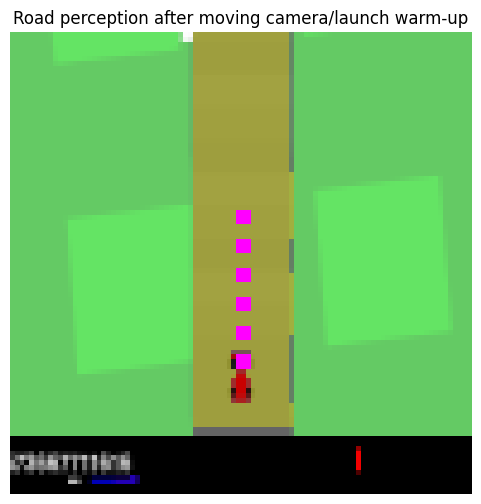

In [10]:
#@title 8. Perception + moving warm-up check
with gym.make(
    ENV_ID,
    render_mode="rgb_array",
    continuous=True,
    domain_randomize=False,
    max_episode_steps=MAX_STEPS,
) as env:
    obs, _, warmup_reward, warm_control, warm_vision = reset_and_warmup(env, SEED)

    print("camera/launch warm-up:", CAMERA_WARMUP_FRAMES, "frames /", CAMERA_WARMUP_FRAMES / SIM_FPS, "simulated s")
    print("warm-up reward:", round(warmup_reward, 3))
    print("warm-up final speed:", round(warm_vision["speed"], 3))
    print("warm-up final control:", [round(float(x), 3) for x in warm_control])
    print(json.dumps(warm_vision, indent=2))

    if warm_vision["speed"] < 1.0:
        raise RuntimeError(
            "Launch warm-up failed: car is still stationary. "
            "Do not start Laya control until this is fixed."
        )

    plt.figure(figsize=(6, 6))
    plt.imshow(perception_overlay(obs))
    plt.title("Road perception after moving camera/launch warm-up")
    plt.axis("off")
    plt.show()


In [11]:
#@title 10. Drive with V29 standalone
policy = LayaCarRacingPolicy(router)

env = gym.make(
    ENV_ID,
    render_mode="rgb_array",
    continuous=True,
    domain_randomize=False,
    max_episode_steps=MAX_STEPS,
)

warmup_frames_for_video = []
obs, _, episode_return, current_control, warm_vision = reset_and_warmup(
    env, SEED, record_frames=warmup_frames_for_video
)
step = CAMERA_WARMUP_FRAMES

reward_history, speed_history = [], []
steer_history, long_history = [], []
visibility_history, confidence_history, blend_history = [], [], []
decision_log, gif_frames = [], []

laya_failures = 0
last_progress_step = step
visited = int(env.unwrapped.tile_visited_count)
terminated = truncated = False
stop_reason = "frame_limit"

# Presentation-only movie HUD. Nothing here feeds back into policy/control.
from PIL import ImageDraw, ImageFont

def _hud_font(size, bold=False):
    candidates = [
        "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf" if bold
        else "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf",
        "/usr/share/fonts/truetype/liberation2/LiberationSans-Bold.ttf" if bold
        else "/usr/share/fonts/truetype/liberation2/LiberationSans-Regular.ttf",
    ]
    for candidate in candidates:
        try:
            return ImageFont.truetype(candidate, size=size)
        except Exception:
            pass
    return ImageFont.load_default()

_HUD_TITLE = _hud_font(22, bold=True)
_HUD_HEAD = _hud_font(15, bold=True)
_HUD_TEXT = _hud_font(14)
_HUD_SMALL = _hud_font(12)

def _fmt_ms(value):
    return "--" if value is None else f"{float(value):.1f} ms"

def make_movie_frame(
    frame,
    *,
    phase,
    step=None,
    vision=None,
    decision=None,
    control=None,
    episode_return=None,
    visited=None,
    total_tiles=None,
):
    """Presentation frame only; returned pixels are never used by the controller."""
    arr = np.asarray(frame, dtype=np.uint8)
    resampling = getattr(PILImage, "Resampling", PILImage)
    game = PILImage.fromarray(arr).resize((432, 432), resampling.BICUBIC)

    canvas = PILImage.new("RGB", (768, 432), (14, 18, 25))
    canvas.paste(game, (0, 0))
    draw = ImageDraw.Draw(canvas)

    try:
        perception = PILImage.fromarray(perception_overlay(arr)).resize(
            (144, 144), resampling.NEAREST
        )
    except Exception:
        perception = PILImage.fromarray(arr).resize((144, 144), resampling.BICUBIC)

    px, py = 570, 62
    canvas.paste(perception, (px, py))
    draw.rectangle(
        (px - 1, py - 1, px + 144, py + 144),
        outline=(115, 132, 156),
        width=1,
    )

    draw.text((452, 14), "Laya x CarRacing", font=_HUD_TITLE, fill=(240, 244, 250))
    draw.text((452, 40), phase, font=_HUD_SMALL, fill=(163, 177, 198))
    draw.text((452, 62), "PERCEPTION", font=_HUD_SMALL, fill=(163, 177, 198))

    y = 220
    line = 23
    if step is not None:
        draw.text((452, y), f"Frame        {int(step):4d}", font=_HUD_TEXT, fill=(233, 238, 246))
        y += line

    if vision is not None:
        draw.text((452, y), f"Speed        {float(vision.get('speed', 0.0)):5.1f}", font=_HUD_TEXT, fill=(233, 238, 246))
        y += line
        draw.text((452, y), f"Road         {str(vision.get('road_direction', 'unknown'))}", font=_HUD_TEXT, fill=(233, 238, 246))
        y += line

    if decision is not None:
        latency = decision.get("latency_ms")
        steering = decision["steering_answer"]["choice"]
        longitudinal = decision["longitudinal_answer"]["choice"]
        confidence = float(decision.get("confidence", 0.0))
        draw.text((452, y), f"Intent       {steering}/{longitudinal}", font=_HUD_TEXT, fill=(233, 238, 246))
        y += line
        draw.text((452, y), f"Confidence   {confidence:5.3f}", font=_HUD_TEXT, fill=(233, 238, 246))
        y += line
        draw.text((452, y), f"Response     {_fmt_ms(latency)}", font=_HUD_HEAD, fill=(255, 218, 121))
        y += line

    if control is not None:
        draw.text(
            (452, y),
            f"Control      steer {float(control[0]):+.2f}  long {float(control[1]):+.2f}",
            font=_HUD_SMALL,
            fill=(205, 214, 228),
        )
        y += line

    if episode_return is not None:
        draw.text((452, y), f"Return       {float(episode_return):+7.1f}", font=_HUD_TEXT, fill=(233, 238, 246))
        y += line

    if visited is not None and total_tiles:
        coverage = 100.0 * float(visited) / max(float(total_tiles), 1.0)
        draw.text(
            (452, y),
            f"Track        {int(visited)}/{int(total_tiles)}  ({coverage:4.1f}%)",
            font=_HUD_TEXT,
            fill=(233, 238, 246),
        )

    draw.line((432, 0, 432, 432), fill=(58, 69, 86), width=2)
    return np.asarray(canvas)

writer = imageio.get_writer(
    VIDEO_PATH,
    format="FFMPEG",
    mode="I",
    fps=SIM_FPS / VIDEO_EVERY,
    codec="libx264",
    pixelformat="yuv420p",
    macro_block_size=1,
)

# Include the warm-up in the video at the same sampling rate.
for i, frame in enumerate(warmup_frames_for_video):
    if i % VIDEO_EVERY == 0:
        writer.append_data(
            make_movie_frame(
                frame,
                phase="camera + launch warm-up",
                step=i + 1,
            )
        )

try:
    while step < MAX_STEPS:
        vision_before = extract_visual_state(
            obs, read_speed(env), read_angular_velocity(env)
        )
        no_progress_frames = step - last_progress_step

        try:
            decision = policy.decide(
                vision_before,
                episode_return,
                step,
                current_control,
            )
        except Exception as error:
            laya_failures += 1
            # Do not kill the whole system for a single model call.
            ref = reference_control(vision_before, force_launch=(vision_before["speed"] < ANTI_STALL_SPEED))
            decision = {
                "steering_answer": {"choice": expected_steering_from_vision(vision_before), "confidence": 0.0, "probabilities": {}, "choice_probability": 0.0, "probability_margin": 0.0},
                "longitudinal_answer": {"choice": "accelerate" if vision_before["speed"] < 20 else "hold", "confidence": 0.0, "probabilities": {}, "choice_probability": 0.0, "probability_margin": 0.0},
                "confidence": 0.0,
                "latency_ms": None,
                "raw_target": ref.copy(),
                "state": {},
                "error": repr(error),
            }

        target, resolution = resolve_control(
            decision,
            vision_before,
            no_progress_frames,
            PREFLIGHT_PASSED,
        )

        rewards = []
        tiles_before = int(env.unwrapped.tile_visited_count)

        for _ in range(min(CONTROL_HORIZON, MAX_STEPS - step)):
            current_control = slew(current_control, target)
            action = to_gym_action(current_control)

            if not np.isfinite(action).all() or action.shape != (3,):
                raise RuntimeError(f"Invalid motor action: {action}")
            if not env.action_space.contains(action):
                raise RuntimeError(f"Motor action outside CarRacing action space: {action}")

            obs, reward, terminated, truncated, _ = env.step(action)
            episode_return += float(reward)
            rewards.append(float(reward))
            step += 1

            vision_after = extract_visual_state(
                obs, read_speed(env), read_angular_velocity(env)
            )

            reward_history.append(float(episode_return))
            speed_history.append(float(vision_after["speed"]))
            steer_history.append(float(current_control[0]))
            long_history.append(float(current_control[1]))
            visibility_history.append(float(vision_after["road_visibility"]))

            current_visited = int(env.unwrapped.tile_visited_count)
            if current_visited > visited:
                visited = current_visited
                last_progress_step = step

            render_frame = None
            if step % VIDEO_EVERY == 0 or step % GIF_EVERY == 0:
                render_frame = env.render()

            movie_frame = None
            if render_frame is not None:
                movie_frame = make_movie_frame(
                    render_frame,
                    phase="local Laya control",
                    step=step,
                    vision=vision_after,
                    decision=decision,
                    control=current_control,
                    episode_return=episode_return,
                    visited=visited,
                    total_tiles=len(env.unwrapped.track),
                )

            if step % VIDEO_EVERY == 0:
                writer.append_data(movie_frame)

            if step % GIF_EVERY == 0:
                resampling = getattr(PILImage, "Resampling", PILImage)
                gif_frames.append(
                    np.asarray(
                        PILImage.fromarray(movie_frame).resize(
                            (640, 360), resampling.LANCZOS
                        )
                    )
                )

            if terminated or truncated:
                stop_reason = "terminated" if terminated else "time_limit"
                break

            if (step - last_progress_step) >= STOP_AFTER_FRAMES:
                stop_reason = "no_new_tiles_after_recovery"
                break

        tiles_after = int(env.unwrapped.tile_visited_count)
        tiles_gained = tiles_after - tiles_before
        horizon_reward = float(np.sum(rewards))
        vision_after = extract_visual_state(
            obs, read_speed(env), read_angular_velocity(env)
        )

        policy.record(decision, horizon_reward, tiles_gained, vision_after)

        entry = {
            "step": int(step),
            "confidence": float(decision["confidence"]),
            "latency_ms": None if decision["latency_ms"] is None else float(decision["latency_ms"]),
            "steering_answer": decision["steering_answer"],
            "longitudinal_answer": decision["longitudinal_answer"],
            "raw_laya_control": resolution["raw_laya_control"],
            "semantic_laya_control": resolution.get("semantic_laya_control"),
            "raw_steering_answer": decision.get("raw_steering_answer"),
            "raw_longitudinal_answer": decision.get("raw_longitudinal_answer"),
            "semantic_overrides": decision.get("semantic_overrides", []),
            "model_confidence": float(decision.get("model_confidence", decision["confidence"])),
            "reference_control": resolution["reference_control"],
            "resolved_target": [float(x) for x in target],
            "applied_control": [float(x) for x in current_control],
            "laya_blend": float(resolution["laya_blend"]),
            "resolution_reasons": resolution["reasons"],
            "expected_steering": resolution["expected_steering"],
            "steering_consistent": resolution["steering_consistent"],
            "pedal_consistent": resolution["pedal_consistent"],
            "reward_horizon": horizon_reward,
            "return_total": float(episode_return),
            "tiles": int(visited),
            "tiles_gained": int(tiles_gained),
            "no_progress_frames": int(step - last_progress_step),
            "vision_before": vision_before,
            "vision_after": vision_after,
        }
        if "error" in decision:
            entry["laya_error"] = decision["error"]

        decision_log.append(entry)
        confidence_history.append(float(decision["confidence"]))
        blend_history.append(float(resolution["laya_blend"]))

        if len(decision_log) <= 15 or len(decision_log) % 20 == 0:
            lat = "ERR" if decision["latency_ms"] is None else f"{decision['latency_ms']:.1f}ms"
            print(
                f"decision {len(decision_log):04d} | step {step:04d} | "
                f"Laya {decision['steering_answer']['choice']}/{decision['longitudinal_answer']['choice']} | "
                f"conf {decision['confidence']:.3f} | blend {resolution['laya_blend']:.2f} | {lat} | "
                f"return {episode_return:+.1f} | steer {current_control[0]:+.2f} | long {current_control[1]:+.2f} | "
                f"road {vision_after['road_direction']} | speed {vision_after['speed']:.1f} | "
                f"tiles {visited}/{len(env.unwrapped.track)} | "
                f"override {','.join(resolution['reasons'])}"
            )

        if terminated or truncated or stop_reason == "no_new_tiles_after_recovery":
            break

    coverage = float(visited) / float(len(env.unwrapped.track)) if len(env.unwrapped.track) else 0.0

finally:
    writer.close()
    env.close()

if gif_frames:
    imageio.mimsave(
        GIF_PATH,
        gif_frames,
        duration=1000.0 * GIF_EVERY / SIM_FPS,
        loop=0,
    )

latencies = [d["latency_ms"] for d in decision_log if d.get("latency_ms") is not None]
confidences = [d["confidence"] for d in decision_log]
blends = [d["laya_blend"] for d in decision_log]

summary = {
    "model": MODEL_ID,
    "device": DEVICE,
    "model_revision": MODEL_REVISION,
    "model_window": MANIFEST.get("window"),
    "bundle_snapshot": MODEL_DIR.name,
    "control_mode": CONTROL_MODE,
    "seed": SEED,
    "camera_warmup_frames": CAMERA_WARMUP_FRAMES,
    "camera_settle_frames": CAMERA_SETTLE_FRAMES,
    "warmup_final_speed": float(warm_vision["speed"]),
    "model_warmup_calls": MODEL_WARMUP_CALLS,
    "model_warmup_total_wall_ms": float(model_warmup_wall_ms),
    "steps_total_including_warmup": int(step),
    "controlled_steps": int(max(0, step - CAMERA_WARMUP_FRAMES)),
    "total_reward_including_warmup": float(episode_return),
    "road_coverage": float(coverage),
    "tiles_visited": int(visited),
    "decisions": int(len(decision_log)),
    "preflight_passed": bool(PREFLIGHT_PASSED),
    "stop_reason": stop_reason,
    "laya_failures": int(laya_failures),
    "mean_laya_latency_ms": float(np.mean(latencies)) if latencies else None,
    "p95_laya_latency_ms": float(np.percentile(latencies, 95)) if latencies else None,
    "mean_laya_confidence": float(np.mean(confidences)) if confidences else None,
    "mean_laya_blend": float(np.mean(blends)) if blends else None,
    "max_laya_blend": float(np.max(blends)) if blends else None,
    "steering_counts": dict(Counter(
        d["steering_answer"]["choice"] for d in decision_log
    )),
    "longitudinal_counts": dict(Counter(
        d["longitudinal_answer"]["choice"] for d in decision_log
    )),
    "override_counts": dict(Counter(
        reason for d in decision_log for reason in d["resolution_reasons"]
    )),
}

Path(LOG_PATH).write_text(
    json.dumps(
        {
            "summary": summary,
            "model_warmup_latencies_ms": warm_latencies,
            "preflight": PREFLIGHT_RESULTS,
            "decisions": decision_log,
        },
        indent=2,
        allow_nan=False,
    ),
    encoding="utf-8",
)

flat_rows = []
for d in decision_log:
    flat_rows.append({
        "step": d["step"],
        "steering": d["steering_answer"]["choice"],
        "longitudinal": d["longitudinal_answer"]["choice"],
        "confidence": d["confidence"],
        "laya_blend": d["laya_blend"],
        "latency_ms": d["latency_ms"],
        "resolved_steer": d["resolved_target"][0],
        "resolved_longitudinal": d["resolved_target"][1],
        "applied_steer": d["applied_control"][0],
        "applied_longitudinal": d["applied_control"][1],
        "reward_horizon": d["reward_horizon"],
        "return_total": d["return_total"],
        "tiles": d["tiles"],
        "tiles_gained": d["tiles_gained"],
        "road_direction": d["vision_before"]["road_direction"],
        "bearing": d["vision_before"]["visible_road_bearing_degrees"],
        "heading": d["vision_before"]["visible_road_heading_degrees"],
        "visibility": d["vision_before"]["road_visibility"],
        "speed": d["vision_before"]["speed"],
        "override": ",".join(d["resolution_reasons"]),
    })

pd.DataFrame(flat_rows).to_csv(CSV_PATH, index=False)

print("\n=== RESULT ===")
print(json.dumps(summary, indent=2))


decision 0001 | step 0054 | Laya straight/hold | conf 0.185 | blend 0.00 | 201.6ms | return +16.5 | steer +0.01 | long +0.12 | road straight | speed 32.0 | tiles 7/319 | override none
decision 0002 | step 0058 | Laya straight/hold | conf 0.310 | blend 0.00 | 154.2ms | return +19.3 | steer -0.03 | long -0.20 | road straight | speed 27.9 | tiles 8/319 | override none
decision 0003 | step 0062 | Laya straight/hold | conf 0.126 | blend 0.00 | 179.1ms | return +22.0 | steer +0.00 | long +0.12 | road straight | speed 28.5 | tiles 9/319 | override none
decision 0004 | step 0066 | Laya straight/hold | conf 0.164 | blend 0.00 | 189.0ms | return +21.6 | steer +0.01 | long +0.12 | road straight | speed 29.3 | tiles 9/319 | override none
decision 0005 | step 0070 | Laya straight/brake | conf 0.219 | blend 0.00 | 205.2ms | return +24.3 | steer +0.00 | long +0.12 | road straight | speed 30.1 | tiles 10/319 | override none
decision 0006 | step 0074 | Laya straight/brake | conf 0.388 | blend 0.00 | 19

MP4:


GIF:


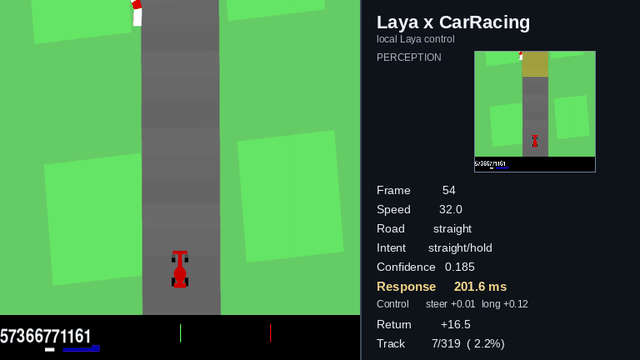


=== LOCAL RESPONSE TIME ===


,metric,latency_ms
0,first model call,1760.9
1,post-warm-up mean,148.3
2,run mean,221.7
3,run median (p50),219.8
4,run p95,238.6
5,run max,865.1


steady-state local Laya rate: 4.5 decisions/s


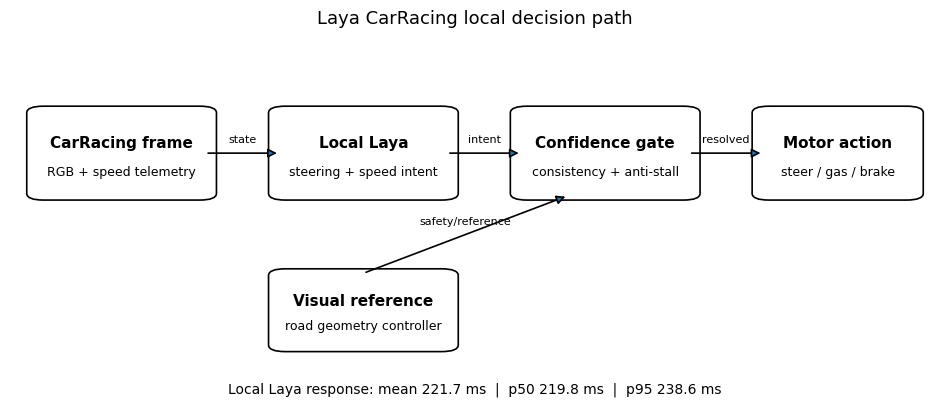

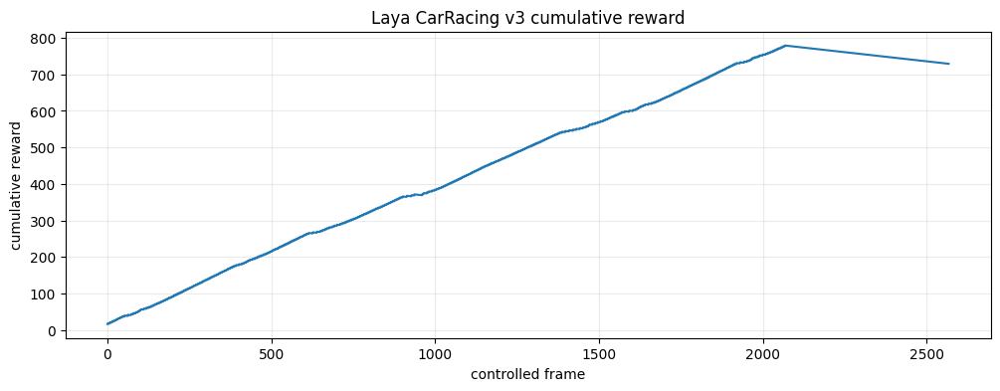

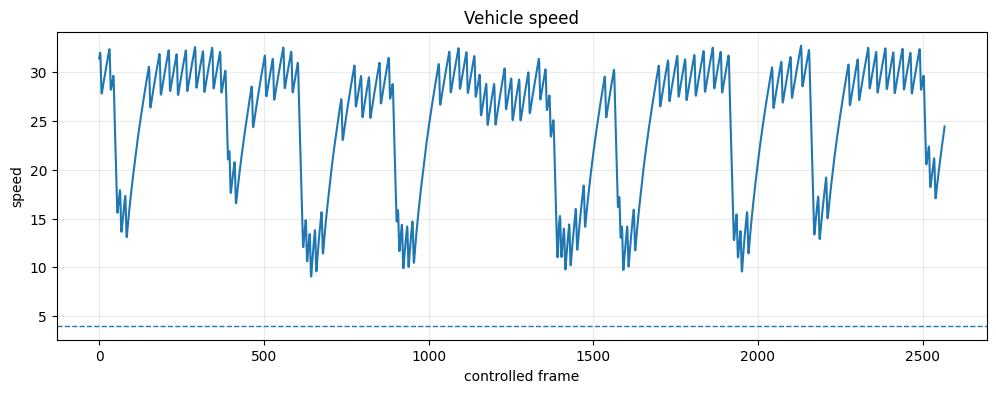

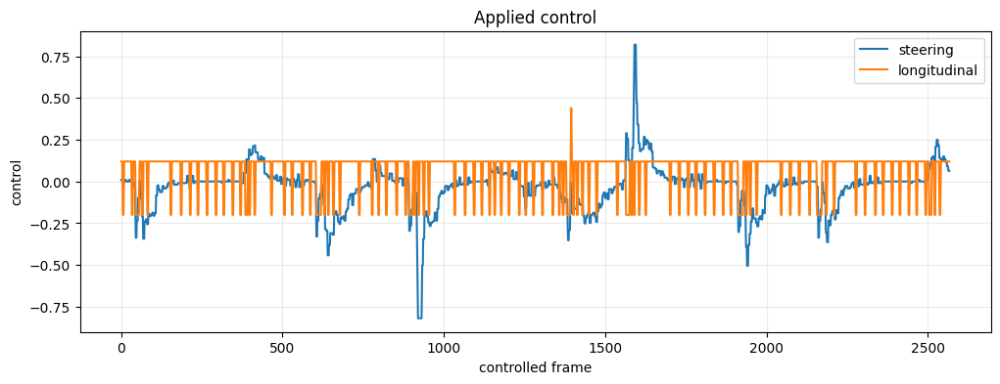

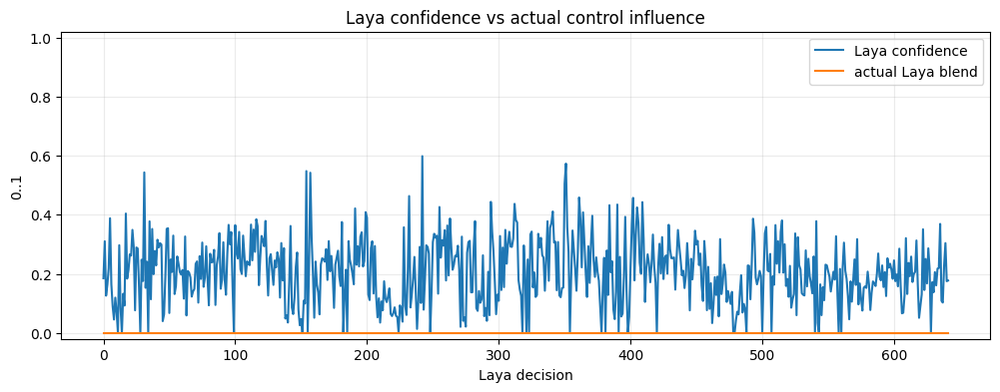

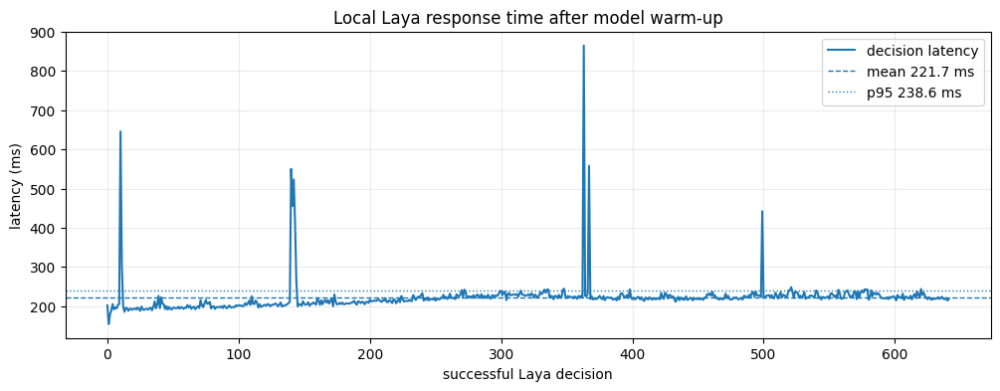

,step,steering,longitudinal,confidence,laya_blend,latency_ms,resolved_steer,resolved_longitudinal,applied_steer,applied_longitudinal,reward_horizon,return_total,tiles,tiles_gained,road_direction,bearing,heading,visibility,speed,override
612,2502,straight,hold,0.192239,0.0,226.529103,-0.009548,0.12,-0.009548,0.12,-0.4,740.395611,316,0,straight,0.000000,-0.954841,1.0,28.877166,tile_progress_recovery
613,2506,straight,hold,0.258430,0.0,217.134733,0.000000,0.12,0.000000,0.12,-0.4,739.995611,316,0,straight,0.000000,0.000000,1.0,29.687118,tile_progress_recovery
614,2510,straight,hold,0.172596,0.0,225.471955,0.000000,0.12,0.000000,0.12,-0.4,739.595611,316,0,straight,0.000000,0.000000,1.0,30.476376,tile_progress_recovery
615,2514,straight,hold,0.199522,0.0,230.674883,0.000000,0.12,0.000000,0.12,-0.4,739.195611,316,0,straight,0.000000,0.000000,1.0,31.247212,tile_progress_recovery
616,2518,straight,hold,0.206775,0.0,220.729106,0.000000,-0.20,0.000000,-0.20,-0.4,738.795611,316,0,straight,0.000000,0.000000,1.0,32.001311,tile_progress_recovery
617,2522,straight,hold,0.312989,0.0,237.491210,0.000000,0.12,0.000000,0.12,-0.4,738.395611,316,0,straight,0.000000,0.000000,1.0,27.879203,tile_progress_recovery
618,2526,straight,hold,0.165808,0.0,229.413447,0.009548,0.12,0.009548,0.12,-0.4,737.995611,316,0,straight,0.000000,0.954841,1.0,28.472604,tile_progress_recovery
619,2530,straight,hold,0.051191,0.0,222.290242,0.000000,0.12,0.000000,0.12,-0.4,737.595611,316,0,straight,0.000000,0.000000,1.0,29.292552,tile_progress_recovery
620,2534,straight,hold,0.090552,0.0,243.779390,0.000000,0.12,0.000000,0.12,-0.4,737.195611,316,0,straight,0.000000,0.000000,1.0,30.091016,tile_progress_recovery
621,2538,straight,hold,0.130370,0.0,228.686880,0.000000,0.12,0.000000,0.12,-0.4,736.795611,316,0,straight,0.000000,0.000000,1.0,30.870437,tile_progress_recovery


video: /content/v29_car_racing_w1024.mp4
gif: /content/v29_car_racing_w1024.gif
preflight: /content/v29_car_racing_w1024_preflight.json
log: /content/v29_car_racing_w1024.json
csv: /content/v29_car_racing_w1024_decisions.csv


In [12]:
#@title 11. Video and diagnostics
print("MP4:")
display(Video(VIDEO_PATH, embed=True, width=960, html_attributes="controls loop"))

if Path(GIF_PATH).exists():
    print("GIF:")
    display(Image(filename=GIF_PATH))

print("\n=== LOCAL RESPONSE TIME ===")
response_rows = []
if warm_latencies:
    response_rows.append({"metric": "first model call", "latency_ms": float(warm_latencies[0])})
if len(warm_latencies) > 1:
    response_rows.append({"metric": "post-warm-up mean", "latency_ms": float(np.mean(warm_latencies[1:]))})
if latencies:
    response_rows.extend([
        {"metric": "run mean", "latency_ms": float(np.mean(latencies))},
        {"metric": "run median (p50)", "latency_ms": float(np.percentile(latencies, 50))},
        {"metric": "run p95", "latency_ms": float(np.percentile(latencies, 95))},
        {"metric": "run max", "latency_ms": float(np.max(latencies))},
    ])

response_df = pd.DataFrame(response_rows)
if not response_df.empty:
    display(response_df.style.format({"latency_ms": "{:.1f}"}))
    if latencies and float(np.mean(latencies)) > 0:
        print(f"steady-state local Laya rate: {1000.0 / float(np.mean(latencies)):.1f} decisions/s")

# Architecture / data-flow diagram. Presentation only.
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(12, 4.8))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")

def _box(x, y, w, h, title, subtitle):
    patch = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.012,rounding_size=0.018",
        linewidth=1.2,
        fill=False,
    )
    ax.add_patch(patch)
    ax.text(x + w/2, y + h*0.62, title, ha="center", va="center", fontsize=11, fontweight="bold")
    ax.text(x + w/2, y + h*0.28, subtitle, ha="center", va="center", fontsize=9)

def _arrow(x1, y1, x2, y2, label=None):
    ax.add_patch(FancyArrowPatch(
        (x1, y1), (x2, y2),
        arrowstyle="-|>",
        mutation_scale=13,
        linewidth=1.2,
    ))
    if label:
        ax.text((x1+x2)/2, (y1+y2)/2 + 0.035, label, ha="center", va="center", fontsize=8)

_box(0.03, 0.58, 0.18, 0.23, "CarRacing frame", "RGB + speed telemetry")
_box(0.29, 0.58, 0.18, 0.23, "Local Laya", "steering + speed intent")
_box(0.55, 0.58, 0.18, 0.23, "Confidence gate", "consistency + anti-stall")
_box(0.81, 0.58, 0.16, 0.23, "Motor action", "steer / gas / brake")
_box(0.29, 0.17, 0.18, 0.20, "Visual reference", "road geometry controller")

_arrow(0.21, 0.695, 0.29, 0.695, "state")
_arrow(0.47, 0.695, 0.55, 0.695, "intent")
_arrow(0.73, 0.695, 0.81, 0.695, "resolved")
_arrow(0.38, 0.37, 0.60, 0.58, "safety/reference")

latency_note = "response time unavailable"
if latencies:
    latency_note = (
        f"Local Laya response: mean {np.mean(latencies):.1f} ms  |  "
        f"p50 {np.percentile(latencies, 50):.1f} ms  |  "
        f"p95 {np.percentile(latencies, 95):.1f} ms"
    )
ax.text(0.5, 0.055, latency_note, ha="center", va="center", fontsize=10)
ax.set_title("Laya CarRacing local decision path", fontsize=13, pad=12)
plt.show()


plt.figure(figsize=(12, 4))
plt.plot(reward_history)
plt.xlabel("controlled frame"); plt.ylabel("cumulative reward")
plt.title("Laya CarRacing v3 cumulative reward")
plt.grid(True, alpha=0.25); plt.show()

plt.figure(figsize=(12, 4))
plt.plot(speed_history)
plt.axhline(ANTI_STALL_SPEED, linestyle="--", linewidth=1)
plt.xlabel("controlled frame"); plt.ylabel("speed")
plt.title("Vehicle speed")
plt.grid(True, alpha=0.25); plt.show()

plt.figure(figsize=(12, 4))
plt.plot(steer_history, label="steering")
plt.plot(long_history, label="longitudinal")
plt.xlabel("controlled frame"); plt.ylabel("control")
plt.title("Applied control")
plt.legend(); plt.grid(True, alpha=0.25); plt.show()

if confidence_history:
    plt.figure(figsize=(12, 4))
    plt.plot(confidence_history, label="Laya confidence")
    plt.plot(blend_history, label="actual Laya blend")
    plt.xlabel("Laya decision"); plt.ylabel("0..1")
    plt.ylim(-0.02, 1.02)
    plt.title("Laya confidence vs actual control influence")
    plt.legend(); plt.grid(True, alpha=0.25); plt.show()

if latencies:
    run_mean_ms = float(np.mean(latencies))
    run_p95_ms = float(np.percentile(latencies, 95))
    plt.figure(figsize=(12, 4))
    plt.plot(latencies, label="decision latency")
    plt.axhline(run_mean_ms, linestyle="--", linewidth=1, label=f"mean {run_mean_ms:.1f} ms")
    plt.axhline(run_p95_ms, linestyle=":", linewidth=1, label=f"p95 {run_p95_ms:.1f} ms")
    plt.xlabel("successful Laya decision"); plt.ylabel("latency (ms)")
    plt.title("Local Laya response time after model warm-up")
    plt.legend()
    plt.grid(True, alpha=0.25); plt.show()

display(pd.DataFrame(flat_rows).tail(30))
print("video:", VIDEO_PATH)
print("gif:", GIF_PATH)
print("preflight:", PREFLIGHT_PATH)
print("log:", LOG_PATH)
print("csv:", CSV_PATH)


In [13]:
#@title 12. Attribute driving to V29 versus safety fallback
valid = [d for d in decision_log if d.get("raw_steering_answer")]
observed = [d for d in valid if d.get("expected_steering") not in (None, "unknown")]
raw_agreement = (
    float(np.mean([d["raw_steering_answer"]["choice"] == d["expected_steering"]
                   for d in observed])) if observed else None
)
corrections = sum(bool(d.get("semantic_overrides")) for d in valid)
n_decisions = max(1, len(decision_log))
attribution = {
    "model": MODEL_ID,
    "bundle_snapshot": MODEL_DIR.name,
    "mode": CONTROL_MODE,
    "seed": SEED,
    "episode_return": summary["total_reward_including_warmup"],
    "coverage": summary["road_coverage"],
    "tiles": summary["tiles_visited"],
    "stop_reason": summary["stop_reason"],
    "model_errors": summary["laya_failures"],
    "raw_steering_agreement_on_observed_road": raw_agreement,
    "semantic_override_fraction": corrections/max(1, len(valid)),
    "mean_model_blend": float(np.mean(blends)) if blends else 0,
    "fraction_decisions_with_majority_model_blend":
        sum(d["laya_blend"] > 0.5 for d in decision_log)/n_decisions,
    "synthetic_raw_steering": RAW_STEER_ACC,
    "synthetic_raw_longitudinal": RAW_LONG_ACC,
    "mean_two_question_ms": summary["mean_laya_latency_ms"],
    "p95_two_question_ms": summary["p95_laya_latency_ms"],
}
REPORT_PATH = str(OUTPUT_DIR / f"v29_report_{CONTROL_MODE}_seed{SEED}.json")
Path(REPORT_PATH).write_text(json.dumps(attribution, indent=2, allow_nan=False))
print(json.dumps(attribution, indent=2))
print("Saved report:", REPORT_PATH)
if CONTROL_MODE == "confidence_hybrid" and attribution["mean_model_blend"] < 0.1:
    print("WARNING: Very little V29 influence: reward mostly measures fallback controller.")
print("Important: raw_laya runs raw typed intents, not direct model motor actions.")


{
  "model": "vtava/Laya-V29-AllGlobal-W1024-Standalone",
  "bundle_snapshot": "39d8fb55197ff41e893f032db227937e15804b6b",
  "mode": "confidence_hybrid",
  "seed": 0,
  "episode_return": 728.7956112852191,
  "coverage": 0.9905956112852664,
  "tiles": 316,
  "stop_reason": "no_new_tiles_after_recovery",
  "model_errors": 0,
  "raw_steering_agreement_on_observed_road": 0.9688473520249221,
  "semantic_override_fraction": 0.04672897196261682,
  "mean_model_blend": 0.0,
  "fraction_decisions_with_majority_model_blend": 0.0,
  "synthetic_raw_steering": 0.9090909090909091,
  "synthetic_raw_longitudinal": 0.0,
  "mean_two_question_ms": 221.69225495794598,
  "p95_two_question_ms": 238.5709396499692
}
Saved report: /content/v29_report_confidence_hybrid_seed0.json
Important: raw_laya runs raw typed intents, not direct model motor actions.
